# HW3 Neural Networks on Oracle Bone Characters
113062273 許晉豪

放在同一個資料夾：`oracle_chars.npz`、`HW3_handwriting_113062273.npz`、`class_handwriting.npz`。
全部在 CPU 上跑（8 threads、deterministic），圖表與 csv 存到 `HW3_results_113062273/`。

In [1]:
import os, time, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
import torch.nn.functional as F
from scipy.ndimage import grey_opening, gaussian_filter, label, binary_dilation
from PIL import Image

SID = 113062273
torch.set_num_threads(8)
torch.use_deterministic_algorithms(True)
OUT = 'HW3_results_113062273'
os.makedirs(OUT, exist_ok=True)
pd.set_option('display.width', 200)
print('torch', torch.__version__, '| numpy', np.__version__)

torch 2.6.0+cu124 | numpy 2.2.6


## Protocol
1. 全部 5,200 張先依類別分層切 80% training（4,160）/ 20% test（1,040），`random_state=SID`。
2. training 再分層切 80% fit（3,328）/ 20% validation（832），`random_state=SID`。fit 用來更新權重，validation 用來比較設定、選 weight decay 和 epoch 數。
3. test 只在 Section 6 Q1b 用一次。所有前處理統計量只用 fit（Section 6 Q1b 重訓時用整個 training）。
4. 權重初始化前 `torch.manual_seed(SID)`，mini-batch 洗牌用 `torch.Generator().manual_seed(SID)`。

In [2]:
d = np.load('oracle_chars.npz')
IMAGES, LABELS = d['images'], d['labels']
NAMES = [str(s) for s in d['class_names']]
RARE = [7, 8, 9]                                           # arrow, time, wood
RAW = IMAGES.reshape(len(IMAGES), -1).astype(np.float32)  # 2,352 values, 0..255

idx_all = np.arange(len(LABELS))
idx_tr, idx_te = train_test_split(idx_all, test_size=0.2, stratify=LABELS, random_state=SID)
idx_fit, idx_val = train_test_split(idx_tr, test_size=0.2, stratify=LABELS[idx_tr], random_state=SID)
assert len(set(idx_tr) & set(idx_te)) == 0 and len(set(idx_fit) & set(idx_val)) == 0

split = pd.DataFrame({'class': NAMES,
                      'fit': np.bincount(LABELS[idx_fit], minlength=10),
                      'validation': np.bincount(LABELS[idx_val], minlength=10),
                      'test': np.bincount(LABELS[idx_te], minlength=10)})
split.loc['total'] = ['total', len(idx_fit), len(idx_val), len(idx_te)]
split.to_csv(f'{OUT}/split_counts.csv', index=False)
print(split)

# default input: the 2,352 values / 255
X = RAW / 255.0
Xf, yf = X[idx_fit], LABELS[idx_fit]
Xv, yv = X[idx_val], LABELS[idx_val]

        class   fit  validation  test
0         big   704         176   220
1         sun   608         152   190
2        moon   512         128   160
3      cattle   416         104   130
4        next   333          83   104
5       field   262          66    82
6         not   205          51    64
7       arrow   147          37    46
8        time    90          22    28
9        wood    51          13    16
total   total  3328         832  1040


## Helpers：模型、訓練、評估

In [3]:
SHALLOW = [192, 192]   # Section 2 Q3: 2 hidden layers
DEEP = [145] * 8       # Section 2 Q3: 8 hidden layers


def make_mlp(widths, act='relu', bn=False, n_in=2352, n_out=10):
    """Linear(+BN)+activation for each hidden layer, then Linear to 10 logits.
    PyTorch default init for nn.Linear: W, b ~ U(-1/sqrt(fan_in), 1/sqrt(fan_in))."""
    A = {'relu': nn.ReLU, 'sigmoid': nn.Sigmoid}[act]
    torch.manual_seed(SID)
    layers, prev = [], n_in
    for w in widths:
        layers.append(nn.Linear(prev, w))
        if bn:
            layers.append(nn.BatchNorm1d(w))
        layers.append(A())
        prev = w
    layers.append(nn.Linear(prev, n_out))
    return nn.Sequential(*layers)


def n_params(net):
    return sum(p.numel() for p in net.parameters() if p.requires_grad)


def layer_table(net):
    rows = []
    for i, m in enumerate([m for m in net.modules() if isinstance(m, nn.Linear)]):
        rows.append({'layer': i + 1, 'shape': f'{m.in_features}->{m.out_features}',
                     'weights': m.weight.numel(), 'biases': m.bias.numel(),
                     'params': m.weight.numel() + m.bias.numel()})
    return pd.DataFrame(rows)


def mse_softmax(logits, y):
    """squared error between the softmax outputs and the one-hot labels (sum over classes, mean over images)"""
    p = torch.softmax(logits, dim=1)
    t = nn.functional.one_hot(y, 10).float()
    return ((p - t) ** 2).sum(dim=1).mean()


LOSSES = {'ce': nn.CrossEntropyLoss(), 'mse': mse_softmax}


@torch.no_grad()
def logits_of(net, A, bs=2048):
    net.eval()
    return torch.cat([net(torch.from_numpy(A[i:i + bs])) for i in range(0, len(A), bs)])


def scores(y, p):
    P, R, F1, _ = precision_recall_fscore_support(y, p, labels=range(10), average='macro', zero_division=0)
    rec = np.array([(p[y == c] == c).sum() / (y == c).sum() for c in range(10)])
    kn = [f'{(p[y == c] == c).sum()}/{(y == c).sum()}' for c in range(10)]
    return dict(acc=accuracy_score(y, p), P=P, R=R, F1=F1, rec=rec, kn=kn,
                rare_avg=rec[RARE].mean())


def score_row(name, y, p):
    s = scores(y, p)
    row = {'network': name, 'accuracy': s['acc'], 'macro-P': s['P'], 'macro-R': s['R'], 'macro-F1': s['F1']}
    for c in RARE:
        row[f'{NAMES[c]} recall'] = f"{s['rec'][c]:.3f} ({s['kn'][c]})"
    row['rare avg'] = s['rare_avg']
    return row


def train(net, Xa, ya, Xb=None, yb=None, epochs=50, opt='adam', lr=1e-3, bs=64, wd=0.0,
          loss='ce', momentum=0.0, keep_best=False, after_epoch=None, augment=None):
    """mini-batch training; after every epoch the loss/macro-F1 on the whole fit set and on the validation set are recorded.
    The timer only counts the weight updates (not the evaluation).
    augment(b): if given, returns the (augmented, standardized) training batch for the positions b."""
    lossf = LOSSES[loss]
    if opt == 'adam':
        o = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)   # betas=(0.9, 0.999), eps=1e-8
    else:
        o = torch.optim.SGD(net.parameters(), lr=lr, momentum=momentum, weight_decay=wd)
    g = torch.Generator().manual_seed(SID)
    Xa_t, ya_t = torch.from_numpy(Xa), torch.from_numpy(ya)
    H = {k: [] for k in ['train_loss', 'train_f1', 'val_loss', 'val_f1', 'time', 'updates']}
    t_total, n_up, best = 0.0, 0, (-1.0, 0, None)
    for ep in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(ya_t), generator=g)
        t0 = time.perf_counter()
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            o.zero_grad()
            xb = Xa_t[b] if augment is None else augment(b)
            l = lossf(net(xb), ya_t[b])
            l.backward()
            o.step()
            n_up += 1
        t_total += time.perf_counter() - t0
        la = logits_of(net, Xa)
        H['train_loss'].append(float(lossf(la, ya_t)))
        H['train_f1'].append(scores(ya, la.argmax(1).numpy())['F1'])
        if Xb is not None:
            lb = logits_of(net, Xb)
            H['val_loss'].append(float(lossf(lb, torch.from_numpy(yb))))
            H['val_f1'].append(scores(yb, lb.argmax(1).numpy())['F1'])
            if keep_best and H['val_f1'][-1] > best[0]:
                best = (H['val_f1'][-1], ep, copy.deepcopy(net.state_dict()))
        H['time'].append(t_total)
        H['updates'].append(n_up)
        if after_epoch is not None:
            after_epoch(ep, net)
    if keep_best:
        H['best_f1'], H['best_epoch'] = best[0], best[1]
        net.load_state_dict(best[2])
    return H


def pred(net, A):
    return logits_of(net, A).argmax(1).numpy()


def plot_cms(items, fname, ncols=None):
    """items: list of (title, y_true, y_pred)"""
    n = len(items); ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.8 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        cm = confusion_matrix(yt, yp, labels=range(10))
        ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(ax=ax, cmap='Blues', colorbar=False,
                                                               values_format='d', xticks_rotation=90)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel('predicted'); ax.set_ylabel('true')
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUT}/{fname}', dpi=130); plt.show()


def show(df, fname):
    df.to_csv(f'{OUT}/{fname}', index=False)
    print(df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

## Section 2 Q3 check：兩個主網路的參數量

In [4]:
for name, w in [('shallow-wide', SHALLOW), ('deep-narrow', DEEP)]:
    print(name, w, n_params(make_mlp(w)))
ps, pd_ = n_params(make_mlp(SHALLOW)), n_params(make_mlp(DEEP))
assert ps == (2352 + 1) * 192 + (192 + 1) * 192 + (192 + 1) * 10
assert pd_ == (2352 + 1) * 145 + 7 * (145 + 1) * 145 + (145 + 1) * 10
print(f'difference = {abs(pd_ - ps)} = {abs(pd_ - ps) / min(ps, pd_) * 100:.4f}% of the smaller total')

shallow-wide [192, 192] 490762


deep-narrow [145, 145, 145, 145, 145, 145, 145, 145] 490835
difference = 73 = 0.0149% of the smaller total


## Section 3 Q1a：ReLU vs sigmoid
同樣是 shallow-wide 架構（2 層 hidden、各 192 units）。Adam lr=1e-3、batch 64、50 epochs、cross-entropy、PyTorch 預設初始化。報告第 50 epoch 的 validation 分數。

network  accuracy  macro-P  macro-R  macro-F1  arrow recall  time recall  wood recall  rare avg  params  train macro-F1
   relu    0.6587   0.5581   0.5237    0.5327 0.459 (17/37) 0.227 (5/22) 0.077 (1/13)    0.2546  490762          0.9965
sigmoid    0.6526   0.5203   0.5022    0.5061 0.351 (13/37) 0.182 (4/22) 0.000 (0/13)    0.1777  490762          0.9395
activation  epoch  train loss  val macro-F1
      relu      1      1.3060        0.2895
      relu      2      1.1467        0.3885
      relu      5      0.9462        0.4246
      relu     10      0.7367        0.4804
      relu     20      0.5244        0.5042
      relu     50      0.0316        0.5327
   sigmoid      1      1.5819        0.1624
   sigmoid      2      1.4161        0.2532
   sigmoid      5      1.1206        0.3619
   sigmoid     10      0.9059        0.4346
   sigmoid     20      0.6388        0.4935
   sigmoid     50      0.1253        0.5061


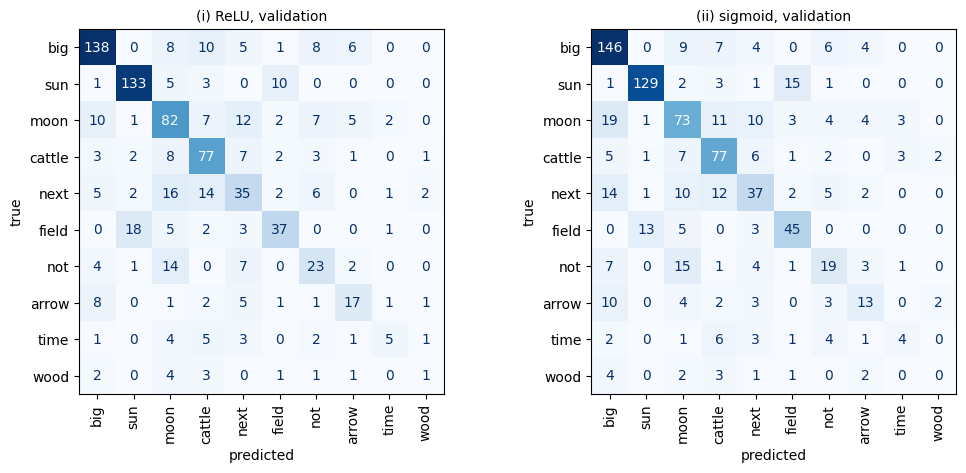

In [5]:
H31, P31, nets31 = {}, {}, {}
for act in ['relu', 'sigmoid']:
    net = make_mlp(SHALLOW, act)
    H31[act] = train(net, Xf, yf, Xv, yv, epochs=50)
    P31[act] = pred(net, Xv)
    nets31[act] = net
rows = []
for act in ['relu', 'sigmoid']:
    r = score_row(act, yv, P31[act]); r['params'] = n_params(nets31[act]); r['train macro-F1'] = H31[act]['train_f1'][-1]
    rows.append(r)
q31 = pd.DataFrame(rows); show(q31, 'q31_scores.csv')

speed = pd.DataFrame([{'activation': a, 'epoch': e, 'train loss': H31[a]['train_loss'][e - 1],
                       'val macro-F1': H31[a]['val_f1'][e - 1]} for a in H31 for e in [1, 2, 5, 10, 20, 50]])
show(speed, 'q31_speed.csv')
plot_cms([('(i) ReLU, validation', yv, P31['relu']), ('(ii) sigmoid, validation', yv, P31['sigmoid'])], 'q31_cm.png')

## Section 3 Q1c：用 ReLU 網路 (i) 的 confusion matrix 手算

In [6]:
cm = confusion_matrix(yv, P31['relu'], labels=range(10))
for c in [0, 9]:
    tp = cm[c, c]; fp = cm[:, c].sum() - tp; fn = cm[c, :].sum() - tp
    p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn); f = 2 * p * r / (p + r) if p + r else 0.0
    print(f'{NAMES[c]}: TP={tp}, FP={fp} (column sum {cm[:, c].sum()}), FN={fn} (row sum {cm[c, :].sum()}) '
          f'-> P={p:.4f}, R={r:.4f}, F1={f:.4f}')
P_, R_, F_, S_ = precision_recall_fscore_support(yv, P31['relu'], labels=range(10), zero_division=0)
per_class = pd.DataFrame({'class': NAMES, 'support': S_, 'precision': P_, 'recall': R_, 'F1': F_})
show(per_class, 'q31c_per_class.csv')
print('accuracy      =', accuracy_score(yv, P31['relu']))
print('macro F1      =', F_.mean())
print('weighted F1   =', (F_ * S_).sum() / S_.sum())
print('macro recall  =', R_.mean(), ' weighted recall =', (R_ * S_).sum() / S_.sum(), '(= accuracy)')

big: TP=138, FP=34 (column sum 172), FN=38 (row sum 176) -> P=0.8023, R=0.7841, F1=0.7931
wood: TP=1, FP=5 (column sum 6), FN=12 (row sum 13) -> P=0.1667, R=0.0769, F1=0.1053
 class  support  precision  recall     F1
   big      176     0.8023  0.7841 0.7931
   sun      152     0.8471  0.8750 0.8608
  moon      128     0.5578  0.6406 0.5964
cattle      104     0.6260  0.7404 0.6784
  next       83     0.4545  0.4217 0.4375
 field       66     0.6607  0.5606 0.6066
   not       51     0.4510  0.4510 0.4510
 arrow       37     0.5152  0.4595 0.4857
  time       22     0.5000  0.2273 0.3125
  wood       13     0.1667  0.0769 0.1053
accuracy      = 0.6586538461538461
macro F1      = 0.5327237818319084
weighted F1   = 0.6525046290622931
macro recall  = 0.5237028987881663  weighted recall = 0.6586538461538461 (= accuracy)


## Section 3 Q2：cross-entropy vs squared error
shallow-wide、ReLU。這題用 plain SGD（lr=0.05、無 momentum、batch 64、50 epochs），讓每次更新量直接等於 lr × gradient，才看得到兩個 loss 的梯度大小差異（Adam 會把每個參數的梯度除以自己的 RMS）。

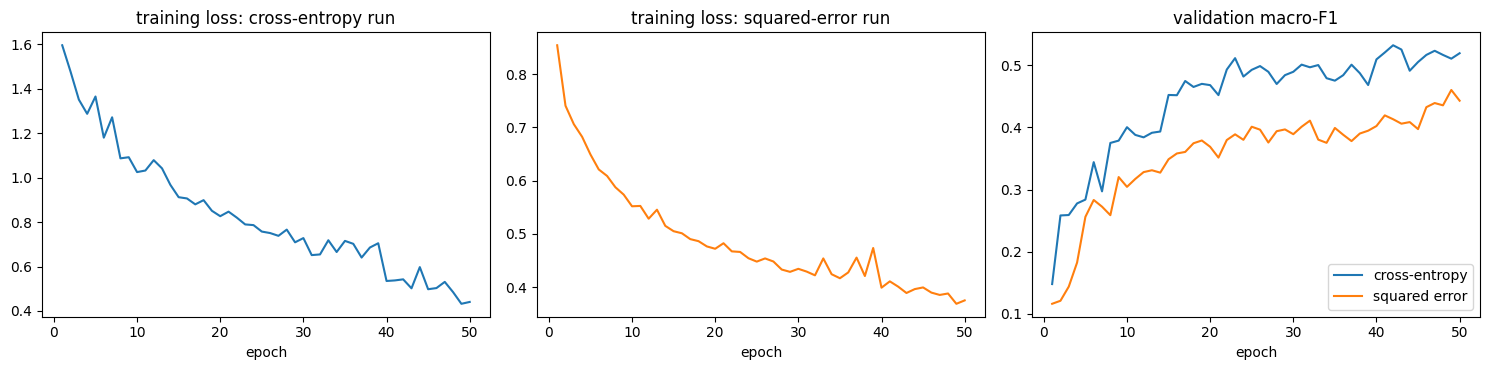

network  accuracy  macro-P  macro-R  macro-F1  arrow recall  time recall  wood recall  rare avg  train macro-F1  fit imgs p_true<0.05
     ce    0.6526   0.5756   0.5172    0.5195 0.297 (11/37) 0.136 (3/22) 0.154 (2/13)    0.1958          0.7690                    56
    mse    0.6226   0.4910   0.4453    0.4431  0.162 (6/37) 0.000 (0/22) 0.000 (0/13)    0.0541          0.5334                   236
 epoch  CE val F1  MSE val F1  CE train F1  MSE train F1
     1     0.1476      0.1159       0.1563        0.1168
     5     0.2837      0.2560       0.2952        0.2555
    10     0.4004      0.3043       0.4374        0.3160
    20     0.4681      0.3688       0.5514        0.3865
    30     0.4896      0.3891       0.6220        0.4389
    50     0.5195      0.4431       0.7690        0.5334


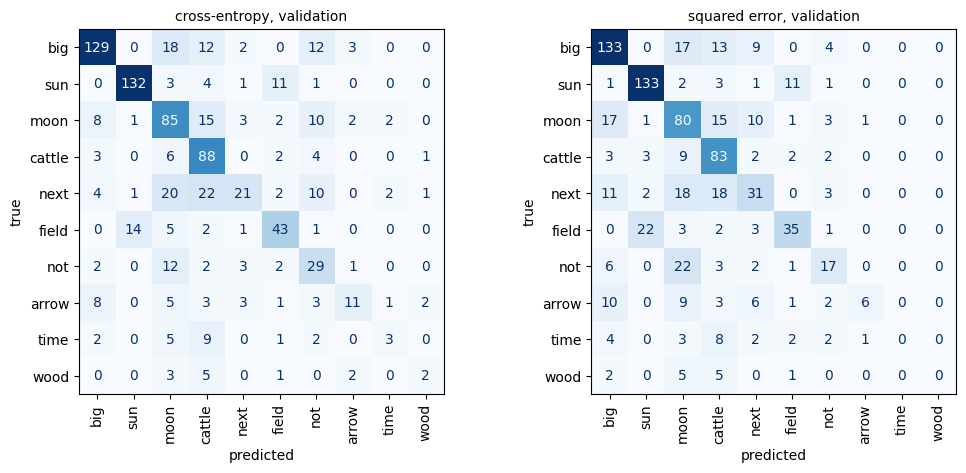

 p_true  p_wrong  dCE/dz_true  dSE/dz_true
 0.5000   0.3000      -0.5000      -0.3450
 0.1000   0.1000      -0.9000      -0.1800
 0.0100   0.9800      -0.9900      -0.0388
 0.0010   0.9980      -0.9990      -0.0040


In [7]:
H32, P32, nets32 = {}, {}, {}
for loss in ['ce', 'mse']:
    net = make_mlp(SHALLOW, 'relu')
    H32[loss] = train(net, Xf, yf, Xv, yv, epochs=50, opt='sgd', lr=0.05, loss=loss)
    P32[loss] = pred(net, Xv); nets32[loss] = net

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ep = np.arange(1, 51)
ax[0].plot(ep, H32['ce']['train_loss'], label='cross-entropy'); ax[0].set_title('training loss: cross-entropy run')
ax[1].plot(ep, H32['mse']['train_loss'], color='C1', label='squared error'); ax[1].set_title('training loss: squared-error run')
for k, lab in [('ce', 'cross-entropy'), ('mse', 'squared error')]:
    ax[2].plot(ep, H32[k]['val_f1'], label=lab)
ax[2].set_title('validation macro-F1'); ax[2].legend()
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(f'{OUT}/q32_curves.png', dpi=130); plt.show()

rows = []
for k in ['ce', 'mse']:
    r = score_row(k, yv, P32[k]); r['train macro-F1'] = H32[k]['train_f1'][-1]
    pf = torch.softmax(logits_of(nets32[k], Xf), 1).numpy()[np.arange(len(yf)), yf]
    r['fit imgs p_true<0.05'] = int((pf < 0.05).sum())
    rows.append(r)
show(pd.DataFrame(rows), 'q32_scores.csv')
show(pd.DataFrame([{'epoch': e, 'CE val F1': H32['ce']['val_f1'][e - 1], 'MSE val F1': H32['mse']['val_f1'][e - 1],
                    'CE train F1': H32['ce']['train_f1'][e - 1], 'MSE train F1': H32['mse']['train_f1'][e - 1]}
                   for e in [1, 5, 10, 20, 30, 50]]), 'q32_by_epoch.csv')
plot_cms([('cross-entropy, validation', yv, P32['ce']), ('squared error, validation', yv, P32['mse'])], 'q32_cm.png')

# derivative w.r.t. the input z_k of the output unit of the true class, for two example outputs
def dz_true(p_true, p_wrong):
    p = np.full(10, (1 - p_true - p_wrong) / 8); p[0], p[1] = p_true, p_wrong
    z = torch.tensor(np.log(p), dtype=torch.float32, requires_grad=True)
    out = []
    for f in ['ce', 'mse']:
        z.grad = None
        LOSSES[f](z[None], torch.tensor([0])).backward()
        out.append(z.grad[0].item())
    return out
show(pd.DataFrame([{'p_true': a, 'p_wrong': b, 'dCE/dz_true': c, 'dSE/dz_true': m}
                   for (a, b) in [(0.5, 0.3), (0.1, 0.1), (0.01, 0.98), (0.001, 0.998)] for c, m in [dz_true(a, b)]]),
     'q32_dz.csv')

## Section 4 Q1：shallow-wide vs deep-narrow
兩個主網路，其餘全同：ReLU、Adam lr=1e-3、batch 64、50 epochs、cross-entropy、預設初始化、輸入 /255。

shallow
 layer     shape  weights  biases  params
     1 2352->192   451584     192  451776
     2  192->192    36864     192   37056
     3   192->10     1920      10    1930
deep
 layer     shape  weights  biases  params
     1 2352->145   341040     145  341185
     2  145->145    21025     145   21170
     3  145->145    21025     145   21170
     4  145->145    21025     145   21170
     5  145->145    21025     145   21170
     6  145->145    21025     145   21170
     7  145->145    21025     145   21170
     8  145->145    21025     145   21170
     9   145->10     1450      10    1460
network  accuracy  macro-P  macro-R  macro-F1  arrow recall  time recall  wood recall  rare avg  train macro-F1  params  train time (s) best val F1 (epoch)
shallow    0.6587   0.5581   0.5237    0.5327 0.459 (17/37) 0.227 (5/22) 0.077 (1/13)    0.2546          0.9965  490762         14.9246         0.5517 (29)
   deep    0.6094   0.4979   0.4680    0.4722  0.162 (6/37) 0.136 (3/22) 0.231 (3/13)  

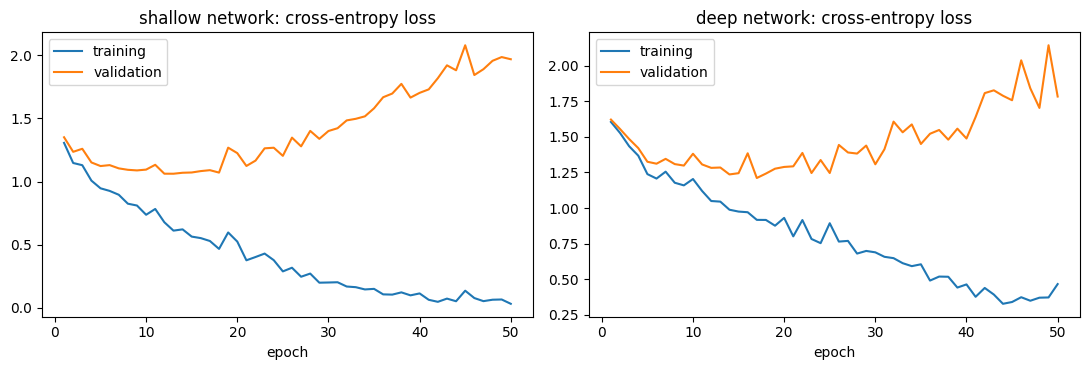

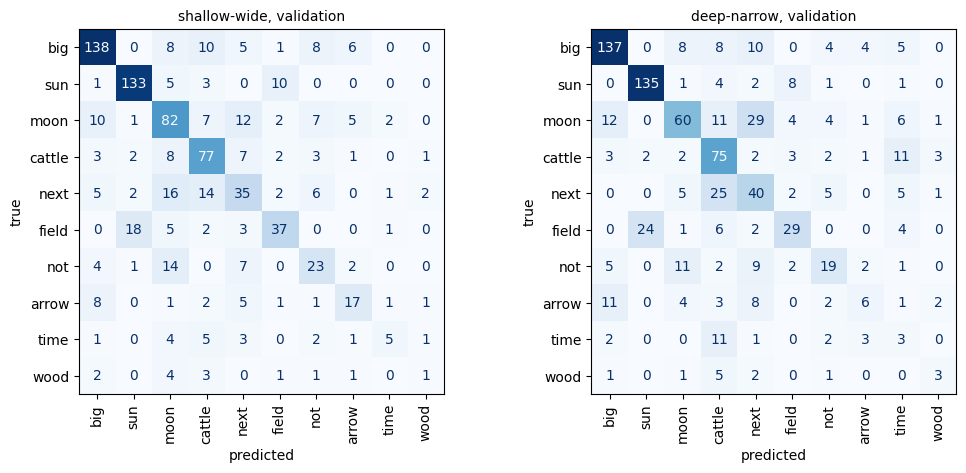

observed gap = 0.0605, bootstrap 95% interval = [0.0117, 0.1109], P(gap<=0) = 0.0105
last 10 epochs val F1  shallow: 0.5325 ± 0.0064   deep: 0.4731 ± 0.0187


In [8]:
H41, P41, nets41 = {}, {}, {}
for name, w in [('shallow', SHALLOW), ('deep', DEEP)]:
    net = make_mlp(w, 'relu')
    H41[name] = train(net, Xf, yf, Xv, yv, epochs=50)
    P41[name] = pred(net, Xv); nets41[name] = net
for name in nets41:
    print(name); show(layer_table(nets41[name]), f'q41_layers_{name}.csv')
rows = []
for name in nets41:
    r = score_row(name, yv, P41[name])
    r['train macro-F1'] = H41[name]['train_f1'][-1]; r['params'] = n_params(nets41[name])
    r['train time (s)'] = H41[name]['time'][-1]
    r['best val F1 (epoch)'] = f"{max(H41[name]['val_f1']):.4f} ({int(np.argmax(H41[name]['val_f1'])) + 1})"
    rows.append(r)
show(pd.DataFrame(rows), 'q41_scores.csv')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, name in enumerate(['shallow', 'deep']):
    ax[i].plot(ep, H41[name]['train_loss'], label='training'); ax[i].plot(ep, H41[name]['val_loss'], label='validation')
    ax[i].set_title(f'{name} network: cross-entropy loss'); ax[i].set_xlabel('epoch'); ax[i].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/q41_loss.png', dpi=130); plt.show()
plot_cms([('shallow-wide, validation', yv, P41['shallow']), ('deep-narrow, validation', yv, P41['deep'])], 'q41_cm.png')

# paired bootstrap over the 832 validation images: how much does the macro-F1 gap move?
rng = np.random.default_rng(SID)
diff = []
for _ in range(2000):
    b = rng.integers(0, len(yv), len(yv))
    diff.append(scores(yv[b], P41['shallow'][b])['F1'] - scores(yv[b], P41['deep'][b])['F1'])
diff = np.array(diff)
print(f'observed gap = {scores(yv, P41["shallow"])["F1"] - scores(yv, P41["deep"])["F1"]:.4f}, '
      f'bootstrap 95% interval = [{np.percentile(diff, 2.5):.4f}, {np.percentile(diff, 97.5):.4f}], '
      f'P(gap<=0) = {(diff <= 0).mean():.4f}')
print('last 10 epochs val F1  shallow: %.4f ± %.4f   deep: %.4f ± %.4f' % (
    np.mean(H41['shallow']['val_f1'][-10:]), np.std(H41['shallow']['val_f1'][-10:]),
    np.mean(H41['deep']['val_f1'][-10:]), np.std(H41['deep']['val_f1'][-10:])))

## Section 4 Q2：10 層 sigmoid，有/沒有 batch normalization
每層寬 128。有 BN 的版本每個 hidden layer 是 Linear → BatchNorm1d → Sigmoid（BN 放在 activation 前）。
plain SGD lr=0.1（所有層共用一個 lr，對應 Q2b 的 LARS）、batch 64、50 epochs、cross-entropy。
梯度 norm 固定用 fit set 的前 256 張，在初始化時和第 1 個 epoch 結束後各算一次（在模型副本上算，train mode）。

 Linear layer  without BN |grad| init  without BN |grad| epoch1  with BN |grad| init  with BN |grad| epoch1
            1                  0.0000                    0.0000               1.2793                 0.9705
            2                  0.0000                    0.0000               0.3281                 0.3390
            3                  0.0000                    0.0000               0.3116                 0.3233
            4                  0.0000                    0.0000               0.2947                 0.3304
            5                  0.0000                    0.0000               0.3192                 0.3272
            6                  0.0001                    0.0000               0.3212                 0.3039
            7                  0.0005                    0.0002               0.3294                 0.2851
            8                  0.0040                    0.0014               0.3282                 0.2713
            9               

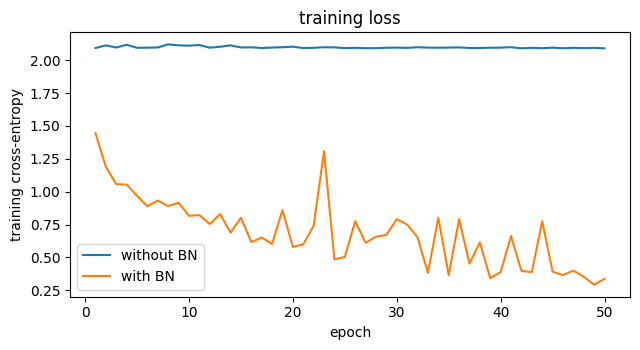

entropy of the class prior = 2.0886484696132714
without BN train loss epoch 1/10/50: [2.0929, 2.1107, 2.0907]  val F1 epoch 50: 0.0349
with BN train loss epoch 1/10/50: [1.4452, 0.8163, 0.3372]  val F1 epoch 50: 0.4793


In [9]:
W10 = [128] * 10
GB_X, GB_y = torch.from_numpy(Xf[:256]), torch.from_numpy(yf[:256])


def grad_info(net):
    m = copy.deepcopy(net); m.train()
    m.zero_grad()
    nn.CrossEntropyLoss()(m(GB_X), GB_y).backward()
    lin = [l for l in m.modules() if isinstance(l, nn.Linear)]
    return [l.weight.grad.norm().item() for l in lin], [l.weight.norm().item() for l in lin]


G42, H42 = {}, {}
for bn in [False, True]:
    tag = 'with BN' if bn else 'without BN'
    net = make_mlp(W10, 'sigmoid', bn=bn)
    G42[tag] = {'init': grad_info(net)}
    def cb(e, n, tag=tag):
        if e == 1:
            G42[tag]['epoch1'] = grad_info(n)
    H42[tag] = train(net, Xf, yf, Xv, yv, epochs=50, opt='sgd', lr=0.1, after_epoch=cb)

rows = []
for i in range(11):
    r = {'Linear layer': i + 1}
    for tag in G42:
        for when in ['init', 'epoch1']:
            r[f'{tag} |grad| {when}'] = G42[tag][when][0][i]
    rows.append(r)
show(pd.DataFrame(rows), 'q42_grad_norms.csv')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for tag in H42:
    ax.plot(ep, H42[tag]['train_loss'], label=tag)
ax.set_xlabel('epoch'); ax.set_ylabel('training cross-entropy'); ax.legend(); ax.set_title('training loss')
plt.tight_layout(); plt.savefig(f'{OUT}/q42_grad_loss.png', dpi=130); plt.show()
pri = np.bincount(yf) / len(yf)
print('entropy of the class prior =', -(pri * np.log(pri)).sum())
for tag in H42:
    print(tag, 'train loss epoch 1/10/50:', [round(H42[tag]['train_loss'][e - 1], 4) for e in [1, 10, 50]],
          ' val F1 epoch 50:', round(H42[tag]['val_f1'][-1], 4))

## Section 4 Q2b：LARS 的 ||w|| / ||∇w||

In [10]:
rows = []
for i in range(11):
    r = {'Linear layer': i + 1}
    for tag in G42:
        for when in ['init', 'epoch1']:
            gn, wn = G42[tag][when][0][i], G42[tag][when][1][i]
            r[f'{tag} ratio {when}'] = wn / gn
    rows.append(r)
lars = pd.DataFrame(rows); show(lars, 'q42b_lars_ratio.csv')
for tag in G42:
    for when in ['init', 'epoch1']:
        g = np.array(G42[tag][when][0])
        print(f'{tag:10s} {when:6s}: |grad| layer1 / layer11 = {g[0] / g[-1]:.3e}')

 Linear layer  without BN ratio init  without BN ratio epoch1  with BN ratio init  with BN ratio epoch1
            1         560828020.1030           987128067.4158              5.1075                6.8119
            2         225176493.2811           677243980.2032             19.8591               19.2416
            3          30944482.8909            95048323.2967             21.0183               20.2793
            4           4317007.4044            12674134.4332             22.1951               19.8172
            5            639480.8950             1792548.6983             20.3914               19.9105
            6             90456.1158              258430.8523             20.3764               21.5568
            7             13218.2136               35013.5866             19.7284               22.8178
            8              1616.3357                4668.5906             19.9036               24.1017
            9               224.8138                 677.4405   

## Section 5 Q1：batch 8 vs batch 512
shallow-wide、ReLU、plain SGD lr=0.05、無 momentum、50 epochs、cross-entropy。training loss 是每個 epoch 結束後在整個 fit set 上算的；計時只算更新權重。

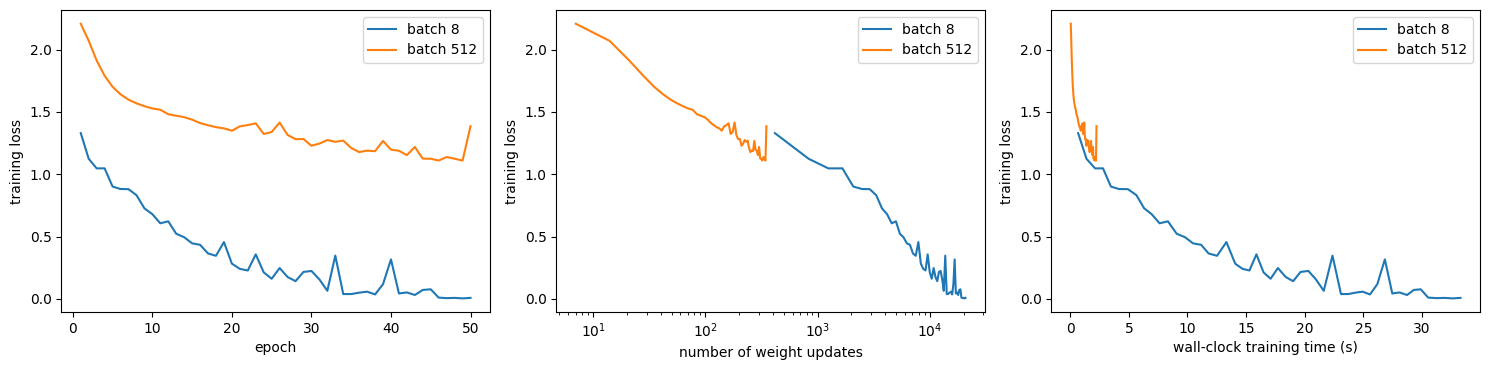

 batch  updates/epoch  total updates  time (s)  ms/update  final train loss  train macro-F1  accuracy  macro-P  macro-R  macro-F1  arrow recall  time recall  wood recall  rare avg
     8            416          20800   33.2978     1.6009            0.0084          0.9979    0.7127   0.6144   0.5804    0.5852 0.459 (17/37) 0.182 (4/22) 0.154 (2/13)    0.2650
   512              7            350    2.2402     6.4004            1.3860          0.3307    0.5096   0.4406   0.3519    0.3250  0.000 (0/37) 0.000 (0/22) 0.000 (0/13)    0.0000


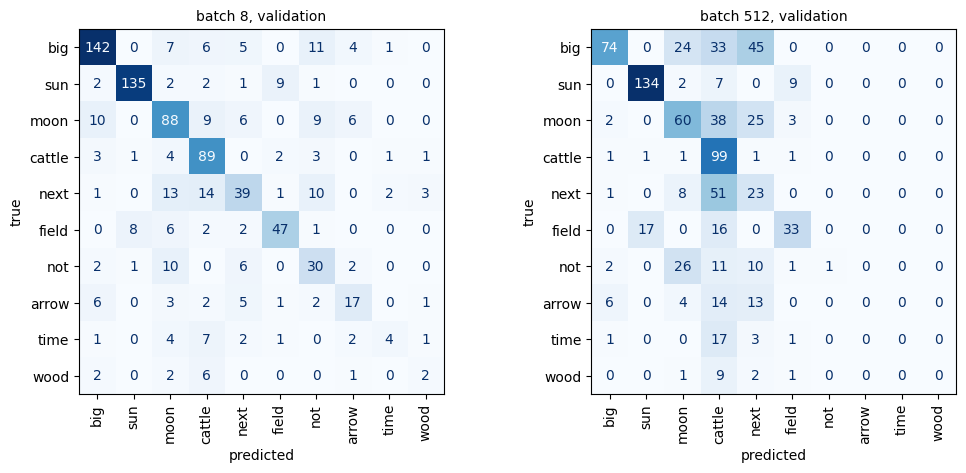

batch   8: mean ||g_batch - g_full|| / ||g_full|| over 100 batches = 1.934


batch 512: mean ||g_batch - g_full|| / ||g_full|| over 100 batches = 0.223


In [11]:
H51, P51, nets51 = {}, {}, {}
for bs in [8, 512]:
    net = make_mlp(SHALLOW, 'relu')
    H51[bs] = train(net, Xf, yf, Xv, yv, epochs=50, opt='sgd', lr=0.05, bs=bs)
    P51[bs] = pred(net, Xv); nets51[bs] = net

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for bs in H51:
    lab = f'batch {bs}'
    ax[0].plot(ep, H51[bs]['train_loss'], label=lab)
    ax[1].plot(H51[bs]['updates'], H51[bs]['train_loss'], label=lab)
    ax[2].plot(H51[bs]['time'], H51[bs]['train_loss'], label=lab)
ax[0].set_xlabel('epoch'); ax[1].set_xlabel('number of weight updates'); ax[1].set_xscale('log')
ax[2].set_xlabel('wall-clock training time (s)')
for a in ax: a.set_ylabel('training loss'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/q51_curves.png', dpi=130); plt.show()

rows = []
for bs in H51:
    r = {'batch': bs, 'updates/epoch': H51[bs]['updates'][0], 'total updates': H51[bs]['updates'][-1],
         'time (s)': H51[bs]['time'][-1], 'ms/update': 1000 * H51[bs]['time'][-1] / H51[bs]['updates'][-1],
         'final train loss': H51[bs]['train_loss'][-1], 'train macro-F1': H51[bs]['train_f1'][-1]}
    r.update({k: v for k, v in score_row(f'batch {bs}', yv, P51[bs]).items() if k != 'network'})
    rows.append(r)
show(pd.DataFrame(rows), 'q51_scores.csv')
plot_cms([('batch 8, validation', yv, P51[8]), ('batch 512, validation', yv, P51[512])], 'q51_cm.png')

# how noisy is one mini-batch gradient? (at initialization, relative to the full fit-set gradient)
net0 = make_mlp(SHALLOW, 'relu')
def flat_grad(xb, yb):
    net0.zero_grad(); nn.CrossEntropyLoss()(net0(xb), yb).backward()
    return torch.cat([p.grad.flatten() for p in net0.parameters()]).clone()
g_full = flat_grad(torch.from_numpy(Xf), torch.from_numpy(yf))
rng = np.random.default_rng(SID)
for bs in [8, 512]:
    rel = [(flat_grad(torch.from_numpy(Xf[b]), torch.from_numpy(yf[b])) - g_full).norm().item() / g_full.norm().item()
           for b in [rng.choice(len(yf), bs, replace=False) for _ in range(100)]]
    print(f'batch {bs:3d}: mean ||g_batch - g_full|| / ||g_full|| over 100 batches = {np.mean(rel):.3f}')

## Section 5 Q2：plain SGD vs SGD with momentum
shallow-wide、ReLU、batch 64、50 epochs、lr 固定 0.01；momentum β=0.9。

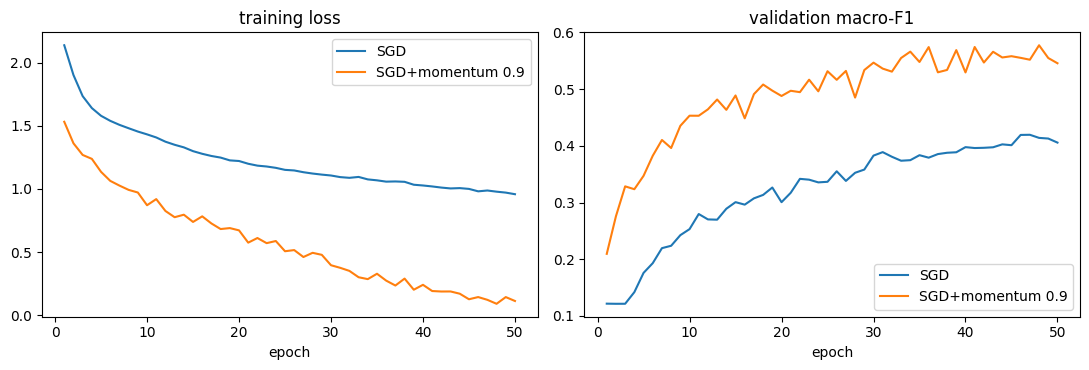

         network  accuracy  macro-P  macro-R  macro-F1  arrow recall   time recall  wood recall  rare avg  train macro-F1  epochs to train loss<1.0
             SGD    0.6094   0.4779   0.4184    0.4057  0.027 (1/37)  0.000 (0/22) 0.000 (0/13)    0.0090          0.4619                        46
SGD+momentum 0.9    0.6659   0.5444   0.5576    0.5455 0.432 (16/37) 0.455 (10/22) 0.000 (0/13)    0.2957          0.9516                         8


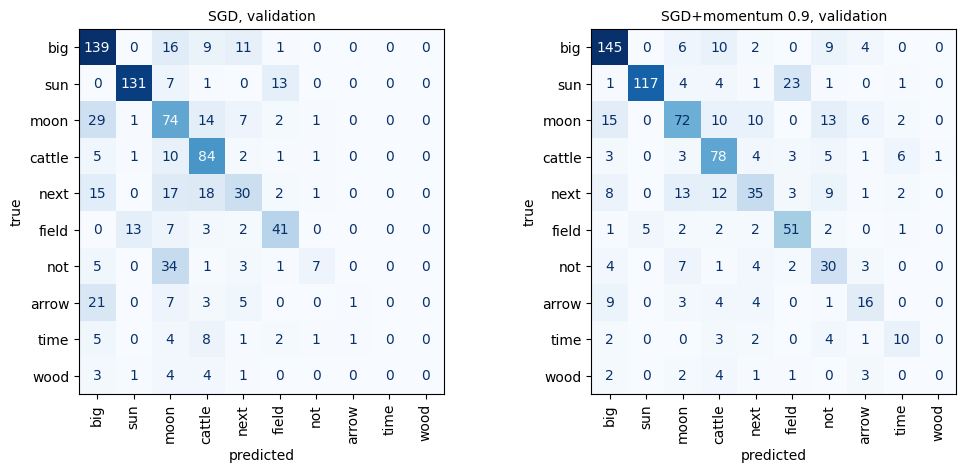

In [12]:
H52, P52 = {}, {}
for name, m in [('SGD', 0.0), ('SGD+momentum 0.9', 0.9)]:
    net = make_mlp(SHALLOW, 'relu')
    H52[name] = train(net, Xf, yf, Xv, yv, epochs=50, opt='sgd', lr=0.01, momentum=m)
    P52[name] = pred(net, Xv)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in H52:
    ax[0].plot(ep, H52[name]['train_loss'], label=name); ax[1].plot(ep, H52[name]['val_f1'], label=name)
ax[0].set_title('training loss'); ax[1].set_title('validation macro-F1')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/q52_curves.png', dpi=130); plt.show()
rows = []
for name in H52:
    r = score_row(name, yv, P52[name]); r['train macro-F1'] = H52[name]['train_f1'][-1]
    r['epochs to train loss<1.0'] = next((e + 1 for e, v in enumerate(H52[name]['train_loss']) if v < 1.0), None)
    rows.append(r)
show(pd.DataFrame(rows), 'q52_scores.csv')
plot_cms([(f'{n}, validation', yv, P52[n]) for n in P52], 'q52_cm.png')

## Section 5 Q3：沒有前處理 vs 我的前處理
shallow-wide、ReLU、Adam lr=1e-3、batch 64、50 epochs。
- raw：直接用 0–255。
- 我的前處理：(1) 除以 255；(2) 逐像素標準化 (x − μ_j) / σ_j，μ_j、σ_j 只用 fit set 算。

per-pixel std on fit set: min 0.0511, max 0.2963


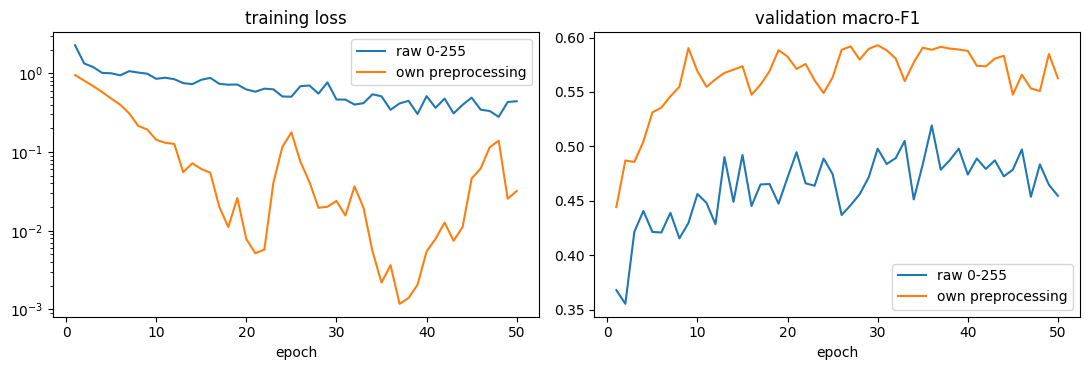

          network  accuracy  macro-P  macro-R  macro-F1  arrow recall  time recall  wood recall  rare avg  train macro-F1  train loss epoch 1
        raw 0-255    0.6070   0.4819   0.4557    0.4547 0.297 (11/37) 0.000 (0/22) 0.077 (1/13)    0.1247          0.7980              2.2709
own preprocessing    0.6791   0.5805   0.5510    0.5626 0.378 (14/37) 0.318 (7/22) 0.231 (3/13)    0.3091          0.9861              0.9492


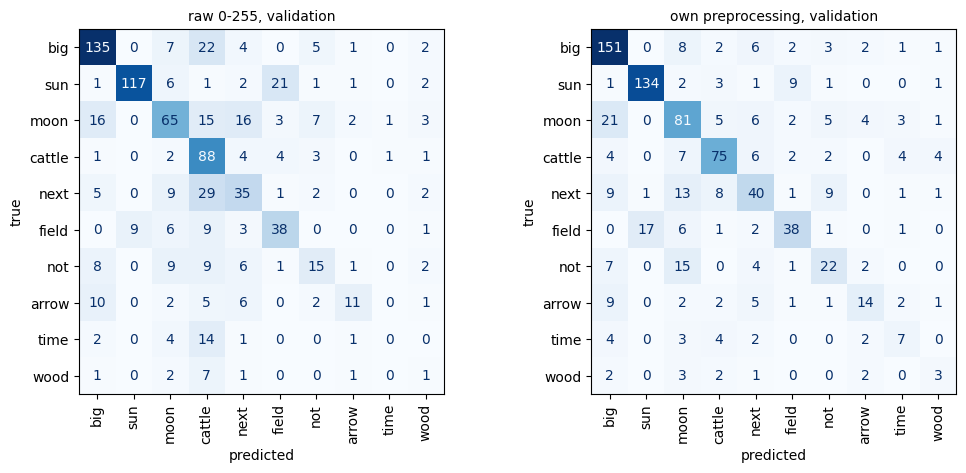

            input  input mean  input std  mean z1  std z1  ReLU active %  sigmoid saturated % (|z|>5)  mean sigmoid slope  ||dL/dW1||  initial loss
        raw 0-255     60.7727    73.1328  -0.8439 53.9481        48.3073                      91.6056              0.0085    302.5825       12.7749
own preprocessing     -0.0000     1.0000   0.0030  0.5957        50.4740                       0.0000              0.2326      1.0607        2.3165
raw 0-255: mean |x_j| = 60.773
own preprocessing: mean |x_j| = 0.733


In [13]:
class Standardizer:
    def fit(self, A):
        self.mu = A.mean(0); self.sd = A.std(0); return self
    def __call__(self, A):
        return ((A - self.mu) / self.sd).astype(np.float32)

std_fit = Standardizer().fit(Xf)
print('per-pixel std on fit set: min %.4f, max %.4f' % (std_fit.sd.min(), std_fit.sd.max()))
INPUTS53 = {'raw 0-255': (RAW[idx_fit], RAW[idx_val]), 'own preprocessing': (std_fit(Xf), std_fit(Xv))}
H53, P53 = {}, {}
for name, (A, B) in INPUTS53.items():
    net = make_mlp(SHALLOW, 'relu')
    H53[name] = train(net, A, yf, B, yv, epochs=50)
    P53[name] = pred(net, B)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in H53:
    ax[0].plot(ep, H53[name]['train_loss'], label=name); ax[1].plot(ep, H53[name]['val_f1'], label=name)
ax[0].set_yscale('log'); ax[0].set_title('training loss'); ax[1].set_title('validation macro-F1')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/q53_curves.png', dpi=130); plt.show()
rows = []
for name in H53:
    r = score_row(name, yv, P53[name]); r['train macro-F1'] = H53[name]['train_f1'][-1]
    r['train loss epoch 1'] = H53[name]['train_loss'][0]; rows.append(r)
show(pd.DataFrame(rows), 'q53_scores.csv')
plot_cms([(f'{n}, validation', yv, P53[n]) for n in P53], 'q53_cm.png')

# what the first hidden layer sees at initialization (same 256 fit images, same initial weights)
rows = []
for name, (A, _) in INPUTS53.items():
    net = make_mlp(SHALLOW, 'relu')
    xb = torch.from_numpy(A[:256]); z = net[0](xb).detach()
    s = torch.sigmoid(z)
    net.zero_grad(); nn.CrossEntropyLoss()(net(xb), GB_y).backward()
    rows.append({'input': name, 'input mean': A.mean(), 'input std': A.std(), 'mean z1': z.mean().item(), 'std z1': z.std().item(),
                 'ReLU active %': 100 * (z > 0).float().mean().item(),
                 'sigmoid saturated % (|z|>5)': 100 * (z.abs() > 5).float().mean().item(),
                 'mean sigmoid slope': (s * (1 - s)).mean().item(),
                 '||dL/dW1||': net[0].weight.grad.norm().item(), 'initial loss': nn.CrossEntropyLoss()(net(xb), GB_y).item()})
show(pd.DataFrame(rows), 'q53_first_layer.csv')
for name, (A, _) in INPUTS53.items():
    print(f'{name}: mean |x_j| = {np.abs(A).mean():.3f}')

## Section 6 Q1：資料增強（L9 p31）
6.1 的網路訓練時每個 batch 做兩件事，validation、test 和標準化的 μ、σ 都用原始拓本：
1. **假手寫：** 40% 的圖換成同一張拓本做出的假手寫。做法：減掉局部背景 → 留最亮的 15–30% 筆畫 → 去掉小碎點 → 細化成 1 px → 用細筆重畫 → 外框縮放成長邊 26 px、置中（跟 6.2a 的手寫轉換同一個格式）。每張拓本先做 4 個版本（seed = 學號）。
2. **平移、縮放、旋轉：** 每張圖隨機平移 ±2 px、縮放 ±10%、旋轉 ±10°。不翻轉，因為翻轉會變成別的字（L9 p31 的 b/d）。


fake handwriting made for 99.9% of the training images x 4 versions


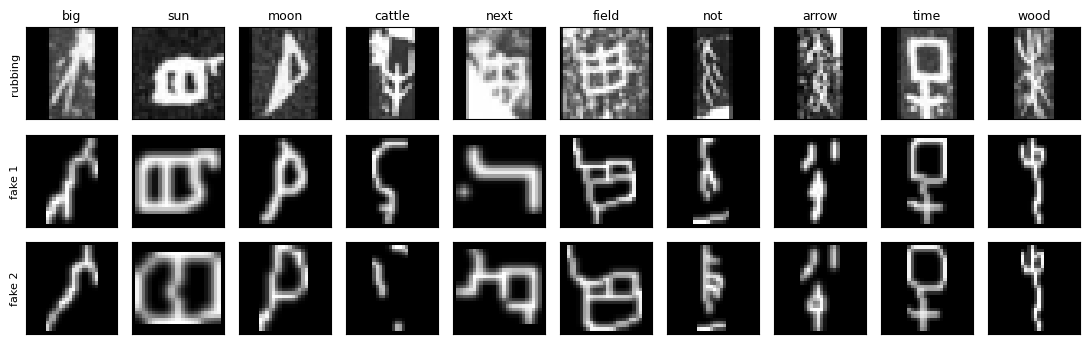

In [14]:
def thin(b):
    """Zhang-Suen thinning: peel boundary pixels until every stroke is 1 px wide."""
    b = np.pad(b.astype(np.uint8), 1)
    while True:
        changed = False
        for step in (0, 1):
            P2, P3, P4, P5 = b[:-2, 1:-1], b[:-2, 2:], b[1:-1, 2:], b[2:, 2:]
            P6, P7, P8, P9 = b[2:, 1:-1], b[2:, :-2], b[1:-1, :-2], b[:-2, :-2]
            nb = [P2, P3, P4, P5, P6, P7, P8, P9]
            B = sum(nb)
            A = sum(((nb[i] == 0) & (nb[(i + 1) % 8] == 1)) for i in range(8))
            m = (b[1:-1, 1:-1] == 1) & (B >= 2) & (B <= 6) & (A == 1)
            m &= ((P2 * P4 * P6 == 0) & (P4 * P6 * P8 == 0)) if step == 0 else ((P2 * P4 * P8 == 0) & (P2 * P6 * P8 == 0))
            if m.any():
                b[1:-1, 1:-1][m] = 0; changed = True
        if not changed:
            return b[1:-1, 1:-1].astype(bool)


def fit_box(g, size=26, thr=0.3):
    ys, xs = np.nonzero(g > thr)
    if not len(ys):
        return g
    box = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = box.shape; s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    box = np.asarray(Image.fromarray(box.astype(np.float32)).resize((nw, nh), Image.BILINEAR))
    out = np.zeros((28, 28), np.float32); y0, x0 = (28 - nh) // 2, (28 - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = box
    return out


def fake_handwriting(img, rng):
    """rubbing -> pen-like image: remove background, keep the bright strokes, drop specks, thin to 1 px, redraw with a thin pen."""
    g = img.astype(np.float32).mean(axis=2) / 255.0
    g = gaussian_filter(g - grey_opening(g, size=(7, 7)), 0.6)
    q = rng.uniform(0.70, 0.85)
    t = max(np.quantile(g[g > 0.02], q) if (g > 0.02).sum() > 20 else 0.1, 0.05)
    lab, n = label(g > t, structure=np.ones((3, 3)))
    if n == 0:
        return None
    sizes = np.bincount(lab.ravel())[1:]
    keep = np.zeros(n + 1, bool); keep[1:] = sizes >= max(6, 0.08 * sizes.max())
    sk = thin(keep[lab])
    if sk.sum() < 5:
        return None
    big = np.asarray(Image.fromarray(sk.astype(np.uint8) * 255).resize((56, 56), Image.NEAREST)) > 0
    if rng.random() < 0.15:
        big = binary_dilation(big)
    p = gaussian_filter(big.astype(np.float32), rng.uniform(0.4, 1.0))
    p = np.asarray(Image.fromarray(p / max(p.max(), 1e-6)).resize((28, 28), Image.BILINEAR))
    p = np.clip(p / max(np.percentile(p, 99), 1e-3), 0, 1)
    return np.clip(fit_box(p), 0, 1)


def make_fakes(images, idx, K, seed):
    """K fake-handwriting versions of every image in idx, as (len(idx), K, 2352) in 0..1, plus a mask of successes."""
    S = np.zeros((len(idx), K, 2352), np.float32); ok = np.zeros((len(idx), K), bool)
    for j, i in enumerate(idx):
        rng = np.random.default_rng([seed, int(i)])
        for k in range(K):
            f = fake_handwriting(images[i], rng)
            if f is not None:
                S[j, k] = np.repeat(f[..., None], 3, -1).ravel(); ok[j, k] = True
    return S, ok


def shift_scale_rotate(xb, g, shift=2, scale=0.1, rot=10):
    """random shift (+-2 px), scale (+-10 %) and rotation (+-10 deg) of a batch of flattened 28x28x3 images."""
    n = len(xb); img = xb.view(n, 28, 28, 3).permute(0, 3, 1, 2)
    u = torch.rand(n, 4, generator=g) * 2 - 1
    s = 1 + u[:, 0] * scale; a = u[:, 1] * rot * np.pi / 180
    th = torch.zeros(n, 2, 3)
    th[:, 0, 0] = torch.cos(a) / s; th[:, 0, 1] = -torch.sin(a) / s
    th[:, 1, 0] = torch.sin(a) / s; th[:, 1, 1] = torch.cos(a) / s
    th[:, :, 2] = u[:, 2:] * shift * 2 / 28
    grid = F.affine_grid(th, img.shape, align_corners=False)
    return F.grid_sample(img, grid, align_corners=False).permute(0, 2, 3, 1).reshape(n, -1)


FAKE_S, FAKE_OK = make_fakes(IMAGES, idx_tr, 4, SID)      # only training images
LOC = np.zeros(len(IMAGES), int); LOC[idx_tr] = np.arange(len(idx_tr))
print('fake handwriting made for %.1f%% of the training images x 4 versions' % (100 * FAKE_OK.mean()))


class Augmenter:
    """training batch for the positions b: p_fake of the images replaced by fake handwriting, then shift/scale/rotate, then standardize."""
    def __init__(self, idx, std, p_fake=0.4):
        self.R = torch.from_numpy(X[idx]); self.S = torch.from_numpy(FAKE_S[LOC[idx]]); self.ok = torch.from_numpy(FAKE_OK[LOC[idx]])
        self.mu, self.sd = torch.from_numpy(std.mu), torch.from_numpy(std.sd)
        self.p = p_fake; self.g = torch.Generator().manual_seed(SID)

    def __call__(self, b):
        xb = self.R[b].clone()
        k = torch.randint(0, self.S.shape[1], (len(b),), generator=self.g)
        use = (torch.rand(len(b), generator=self.g) < self.p) & self.ok[b, k]
        xb[use] = self.S[b[use], k[use]]
        xb = shift_scale_rotate(xb, self.g)
        return ((xb - self.mu) / self.sd).float()


fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
for c in range(10):
    j = np.flatnonzero(LABELS[idx_tr] == c)[0]
    axes[0, c].imshow(IMAGES[idx_tr[j]]); axes[0, c].set_title(NAMES[c], fontsize=9)
    axes[1, c].imshow(FAKE_S[j, 0].reshape(28, 28, 3)); axes[2, c].imshow(FAKE_S[j, 1].reshape(28, 28, 3))
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel('rubbing', fontsize=8); axes[1, 0].set_ylabel('fake 1', fontsize=8); axes[2, 0].set_ylabel('fake 2', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/q61_fake_handwriting.png', dpi=130); plt.show()


## Section 6 Q1a：調 weight decay（L2 penalty）
shallow-wide（Section 4 Q1b 選的）、ReLU、我的前處理（Section 5 Q3）＋上面的資料增強、Adam lr=1e-3 固定、batch 64、cross-entropy。
Adam 的 `weight_decay=λ` 是把 λw 加到梯度上，等於在 loss 加 (λ/2)‖w‖²（所有 weights 和 biases）。
搜尋 8 個 λ：0 和 1e-4 到 1e-1 的 half-decade 格點。每個 λ 最多 200 epochs（有資料增強，學得比較慢），以 validation macro-F1 最高的 epoch 代表該 λ；λ 和 epoch 數一起選。


 weight decay  best val macro-F1  best epoch  train macro-F1 @best  val macro-F1 @200  train macro-F1 @200
       0.0000             0.6951         164                0.9125             0.6849               0.8984
       0.0001             0.6790         173                0.8981             0.6575               0.8930
       0.0003             0.6923         146                0.8405             0.6696               0.8685
       0.0010             0.7124         164                0.8275             0.6540               0.8374
       0.0030             0.6754         149                0.7366             0.6390               0.7513
       0.0100             0.5228         157                0.5259             0.4904               0.5033
       0.0300             0.4294         149                0.4400             0.3811               0.4224
       0.1000             0.2578         139                0.2644             0.2286               0.2366
chosen: weight decay = 0.001 , epochs

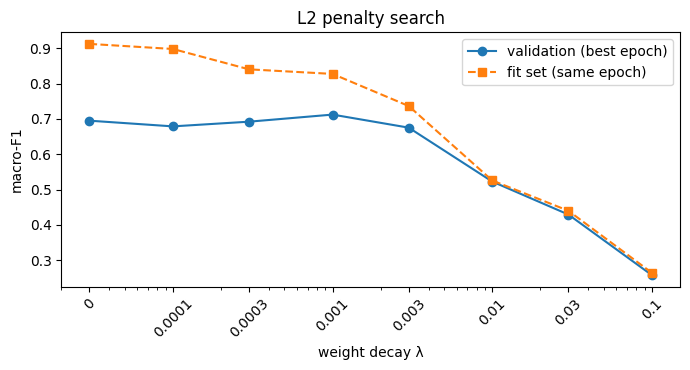

                         network  accuracy  macro-P  macro-R  macro-F1  arrow recall   time recall  wood recall  rare avg
λ=0.001, 164 epochs (validation)    0.7716   0.7444   0.6956    0.7124 0.486 (18/37) 0.545 (12/22) 0.538 (7/13)    0.5235


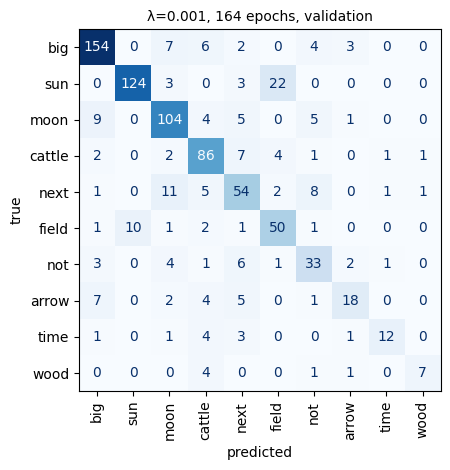

In [15]:
WD_GRID = [0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
Xf_s, Xv_s = std_fit(Xf), std_fit(Xv)
rows, H61, nets61 = [], {}, {}
for wd in WD_GRID:
    net = make_mlp(SHALLOW, 'relu')
    H = train(net, Xf_s, yf, Xv_s, yv, epochs=200, wd=wd, keep_best=True, augment=Augmenter(idx_fit, std_fit))
    H61[wd], nets61[wd] = H, net     # keep_best: net holds the weights of the best epoch
    e = H['best_epoch']
    rows.append({'weight decay': wd, 'best val macro-F1': H['best_f1'], 'best epoch': e,
                 'train macro-F1 @best': H['train_f1'][e - 1], 'val macro-F1 @200': H['val_f1'][-1],
                 'train macro-F1 @200': H['train_f1'][-1]})
q61 = pd.DataFrame(rows); show(q61, 'q61_search.csv')
best_i = int(q61['best val macro-F1'].idxmax())
WD_BEST, EP_BEST = WD_GRID[best_i], int(q61.loc[best_i, 'best epoch'])
print('chosen: weight decay =', WD_BEST, ', epochs =', EP_BEST)

xs = np.array([3e-5] + WD_GRID[1:])   # plot λ=0 at 3e-5
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogx(xs, q61['best val macro-F1'], 'o-', label='validation (best epoch)')
ax.semilogx(xs, q61['train macro-F1 @best'], 's--', label='fit set (same epoch)')
ax.set_xticks(xs); ax.set_xticklabels(['0'] + [f'{v:g}' for v in WD_GRID[1:]], rotation=45)
ax.set_xlabel('weight decay λ'); ax.set_ylabel('macro-F1'); ax.legend(); ax.set_title('L2 penalty search')
plt.tight_layout(); plt.savefig(f'{OUT}/q61_search.png', dpi=130); plt.show()

P61v = pred(nets61[WD_BEST], Xv_s)
assert abs(scores(yv, P61v)['F1'] - q61.loc[best_i, 'best val macro-F1']) < 1e-12   # same run, same epoch
q61v = pd.DataFrame([score_row(f'λ={WD_BEST}, {EP_BEST} epochs (validation)', yv, P61v)]); show(q61v, 'q61_selected_val.csv')
plot_cms([(f'λ={WD_BEST}, {EP_BEST} epochs, validation', yv, P61v)], 'q61_cm_val.png')

## Section 6 Q1b：用整個 training（fit + validation）重訓，test 只看這一次
標準化的 μ、σ 改用整個 training 4,160 張重新算；λ 與 epoch 數用 Q1a 選好的，資料增強同上（假手寫只用 training 的圖做）。

         network  accuracy  macro-P  macro-R  macro-F1  arrow recall   time recall  wood recall  rare avg
validation (Q1a)    0.7716   0.7444   0.6956    0.7124 0.486 (18/37) 0.545 (12/22) 0.538 (7/13)    0.5235
      test (Q1b)    0.7798   0.7080   0.6749    0.6856 0.413 (19/46) 0.393 (11/28) 0.562 (9/16)    0.4561


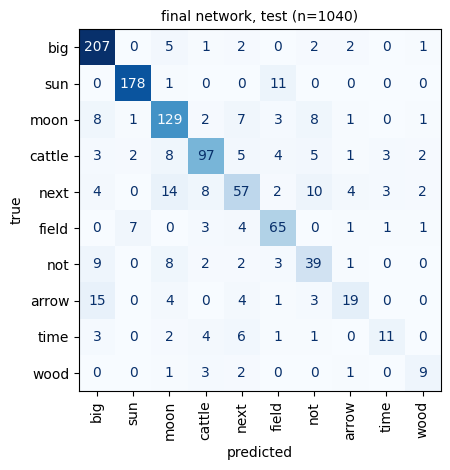

In [16]:
Xtr, ytr = X[idx_tr], LABELS[idx_tr]
Xte, yte = X[idx_te], LABELS[idx_te]
std_tr = Standardizer().fit(Xtr)
final_net = make_mlp(SHALLOW, 'relu')
H_final = train(final_net, std_tr(Xtr), ytr, epochs=EP_BEST, wd=WD_BEST, augment=Augmenter(idx_tr, std_tr))
torch.save(final_net.state_dict(), f'{OUT}/final_model.pt')
P_te = pred(final_net, std_tr(Xte))
q61b = pd.DataFrame([score_row('validation (Q1a)', yv, P61v), score_row('test (Q1b)', yte, P_te)])
show(q61b, 'q61b_test.csv')
plot_cms([(f'final network, test (n={len(yte)})', yte, P_te)], 'q61b_cm_test.png')

## Section 6 Q2a：把手寫字轉成資料集的格式
同一個規則套在全部 30 張（之後也套在 class_handwriting）：
1. 三個 channel 取平均（彩色墨水也變成灰階）。
2. 若平均值 < 中位數（少數像素比較暗 = 深色字、淺色紙）就反相 255 − x，變成亮字暗底。
3. 減掉局部背景：x − grey_opening(x, 9×9)（white top-hat，去掉紙張底色和陰影），再除以第 99 百分位數並截在 [0, 1]：背景 → 0、筆畫 → 1。
4. 取 >0.3 的像素的外框，等比例縮放成長邊 26 px，放到 28×28 黑底的中央（資料集的字也是長邊撐滿、置中、旁邊補黑）。
5. 乘 255、複製成 3 個相同 channel、存成 uint8。

之後跟訓練時一樣：除以 255，再用整個 training 的 μ、σ 標準化。

分類時（6.2b、c、d）：手寫字每個字都是 3 張，各類一樣多，但網路學到的是 training 的類別比例。依 Bayes 定理（L5）P(C|x) ∝ P(x|C)P(C)，把 training 的 prior 換成均勻：logit − log P_train(C) 再取 argmax。網路本身不變，也沒有可調的參數。

channel spread (max-min over RGB), mean over pixels: raw 0.000, converted 0.000


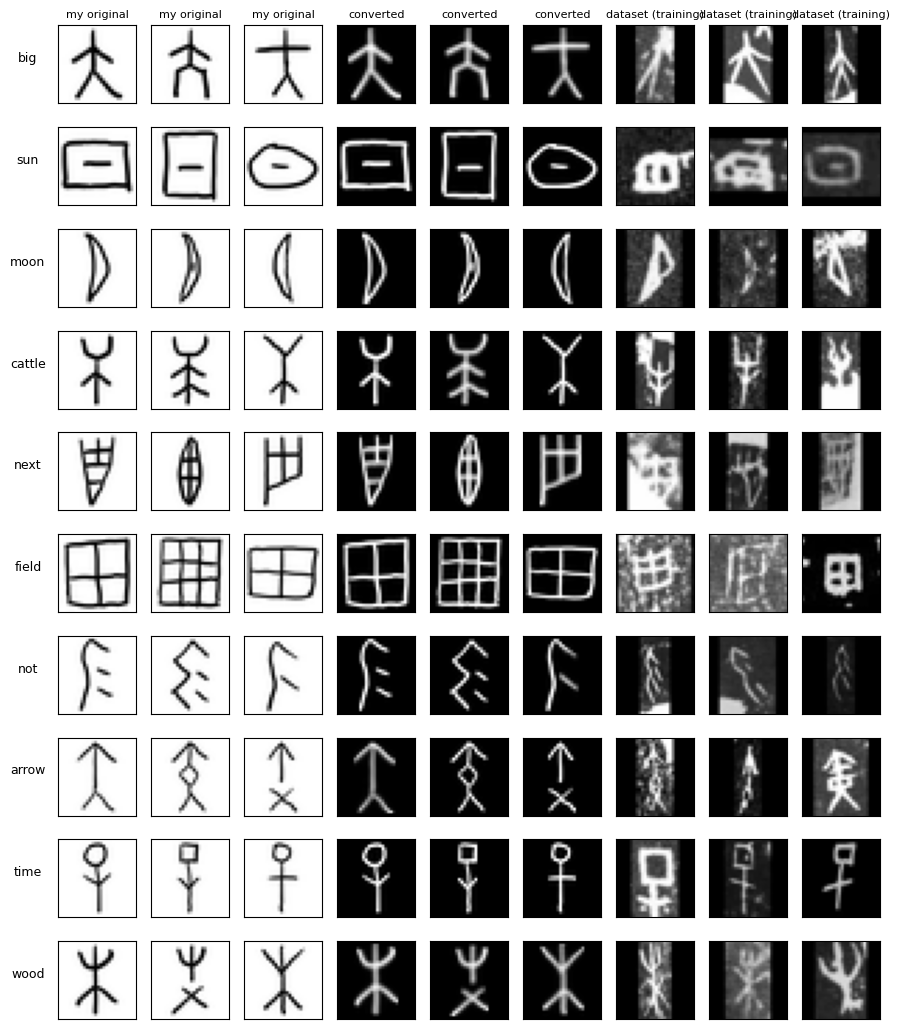

In [17]:
def convert(img, gray=True, fit_box=True):
    g = img.astype(np.float32)
    if gray:
        g = g.mean(axis=2, keepdims=True)                          # step 1
    if g.mean() < np.median(g):                                    # step 2
        g = 255.0 - g
    g = g - grey_opening(g, size=(9, 9, 1))                        # step 3
    g = np.clip(g / max(np.percentile(g, 99), 1.0), 0, 1)
    if fit_box:                                                    # step 4
        ys, xs = np.nonzero(g.max(axis=2) > 0.3)
        if len(ys):
            box = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
            h, w = box.shape[:2]; s = 26.0 / max(h, w)
            nh, nw = max(1, round(h * s)), max(1, round(w * s))
            box = np.stack([np.asarray(Image.fromarray(box[..., c]).resize((nw, nh), Image.BILINEAR))
                            for c in range(box.shape[2])], -1)
            out = np.zeros((28, 28, box.shape[2]), np.float32)
            y0, x0 = (28 - nh) // 2, (28 - nw) // 2
            out[y0:y0 + nh, x0:x0 + nw] = box
            g = out
    g = np.broadcast_to(np.clip(g, 0, 1) * 255, (28, 28, 3))       # step 5
    return np.round(g).astype(np.uint8)


def to_input(imgs_uint8):
    return std_tr(imgs_uint8.reshape(len(imgs_uint8), -1).astype(np.float32) / 255.0)


LOG_PRIOR = np.log(np.bincount(ytr, minlength=10) / len(ytr))


def pred_hw(net, imgs_uint8):
    """handwriting: same network, training prior replaced by a uniform prior (Bayes)"""
    return (logits_of(net, to_input(imgs_uint8)).numpy() - LOG_PRIOR).argmax(1)


hw = np.load('HW3_handwriting_113062273.npz')
HW_RAW, HW_Y = hw['images'], hw['labels']
assert HW_RAW.shape == (30, 28, 28, 3) and HW_RAW.dtype == np.uint8 and (HW_Y == np.repeat(np.arange(10), 3)).all()
HW_CONV = np.stack([convert(im) for im in HW_RAW])
print('channel spread (max-min over RGB), mean over pixels: raw %.3f, converted %.3f' % (
    (HW_RAW.max(-1).astype(int) - HW_RAW.min(-1)).mean(), (HW_CONV.max(-1).astype(int) - HW_CONV.min(-1)).mean()))

fig, axes = plt.subplots(10, 9, figsize=(9, 10.5))
for c in range(10):
    for k in range(3):
        axes[c, k].imshow(HW_RAW[3 * c + k]); axes[c, 3 + k].imshow(HW_CONV[3 * c + k])
    for k, i in enumerate(idx_tr[LABELS[idx_tr] == c][:3]):
        axes[c, 6 + k].imshow(IMAGES[i])
    axes[c, 0].set_ylabel(NAMES[c], rotation=0, labelpad=22, fontsize=9)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
for k, t in enumerate(['my original'] * 3 + ['converted'] * 3 + ['dataset (training)'] * 3):
    axes[0, k].set_title(t, fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/q62a_conversion.png', dpi=130); plt.show()

## Section 6 Q2b：用 Q1b 的網路分類 30 張手寫字（不重訓）

accuracy = 0.8667 (26/30); without the prior correction 21/30; test accuracy = 0.7798
 class  correct (of 3)        predicted as
   big               3       big, big, big
   sun               3       sun, sun, sun
  moon               3    moon, moon, moon
cattle               1  cattle, time, wood
  next               2   next, next, field
 field               3 field, field, field
   not               3       not, not, not
 arrow               3 arrow, arrow, arrow
  time               3    time, time, time
  wood               2    time, wood, wood


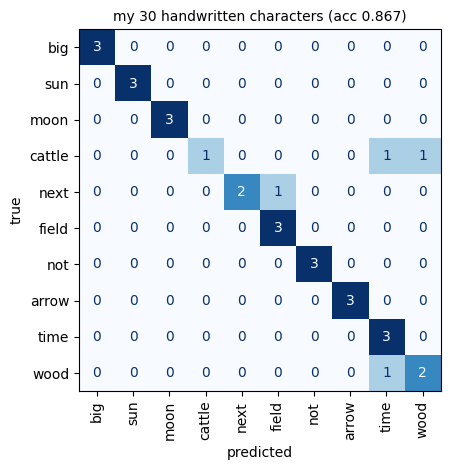

copy 1 (main form): 9/10 correct
copy 2 (variant 1): 9/10 correct
copy 3 (variant 2): 8/10 correct


In [18]:
P_hw = pred_hw(final_net, HW_CONV)
P_hw_argmax = pred(final_net, to_input(HW_CONV))   # without the prior correction
acc_hw = (P_hw == HW_Y).mean()
per_char = pd.DataFrame({'class': NAMES, 'correct (of 3)': [(P_hw[HW_Y == c] == c).sum() for c in range(10)],
                         'predicted as': [', '.join(NAMES[p] for p in P_hw[HW_Y == c]) for c in range(10)]})
print(f'accuracy = {acc_hw:.4f} ({(P_hw == HW_Y).sum()}/30); without the prior correction {(P_hw_argmax == HW_Y).sum()}/30; test accuracy = {accuracy_score(yte, P_te):.4f}')
show(per_char, 'q62b_per_char.csv')
plot_cms([(f'my 30 handwritten characters (acc {acc_hw:.3f})', HW_Y, P_hw)], 'q62b_cm.png')
for k, form in enumerate(['main form', 'variant 1', 'variant 2']):
    print(f'copy {k + 1} ({form}): {(P_hw[k::3] == HW_Y[k::3]).sum()}/10 correct')


## Section 6 Q2c：為什麼準 / 不準
1. 比較背景、雜訊、筆畫、大小位置、各類平均影像。
2. 網路怎麼用每個像素：第一層權重的大小、標準化用的 σ_j。
3. 三個 channel：網路對 channel 差異的反應。
4. 實驗：(1) 模擬藍色墨水、拿掉第 1 步（channel 平均）；(2) 同樣的訓練但不用假手寫。

                  set  mean pixel  % pixels = 0  % pixels > 128  mean of pixels <= 64 (background)  mean width of columns with a pixel > 64
dataset training part     60.4749       38.2945         17.5597                            15.0944                                  16.9077
      my converted 30     29.2126       67.2874         11.3265                             2.5183                                  15.2000


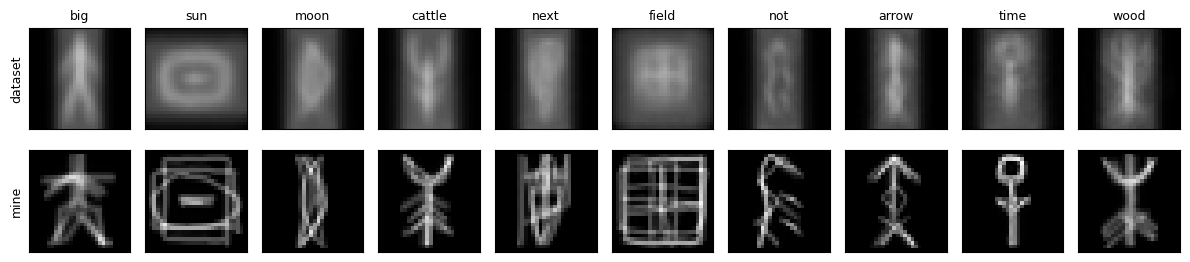

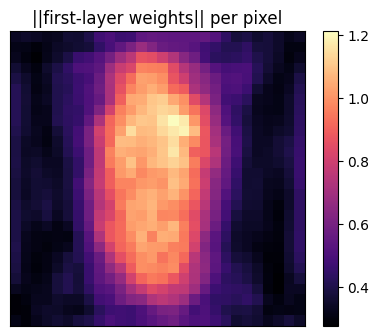

standardized input of my images: mean -0.490, max 6.29, % of values > 5: 0.09
standardized input of training images: mean -0.000, max 19.86, % of values > 5: 0.27
||W_R - W_G|| / ||W_R||  at init: 1.4152   after training: 0.0039
||W_R - W_B|| / ||W_R||  after training: 0.0039
corr(W_R, W_G) after training: 1.0000
                              input  accuracy correct  predictions changed vs mine  channel spread
          my conversion (steps 1-5)    0.8667   26/30                            0          0.0000
without step 1 (no channel average)    0.8667   26/30                            0          0.0000
            blue ink, my conversion    0.8667   26/30                            0          0.0000
           blue ink, without step 1    0.7333   22/30                            4         25.2222


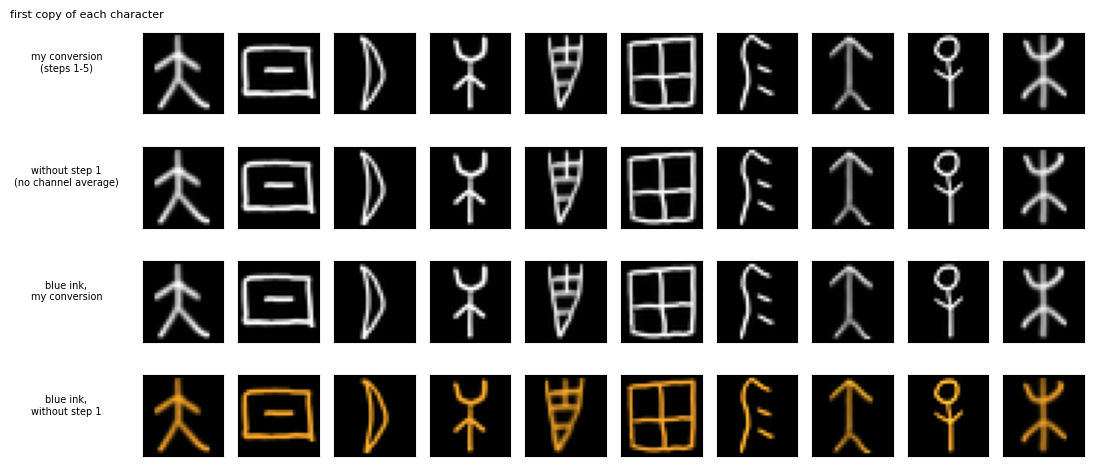

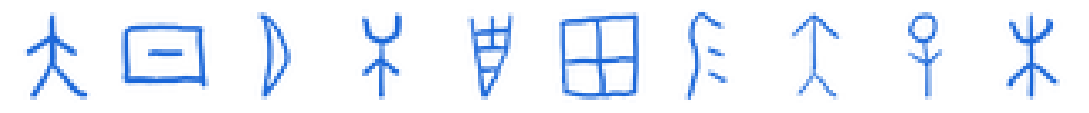

                             training correct
with fake handwriting (final network)   26/30
             without fake handwriting   20/30


In [19]:
def img_stats(imgs):
    g = imgs[..., 0].astype(np.float32)          # channels are equal after conversion / in the dataset
    flat = g.reshape(len(g), -1)
    cols = (g > 64).any(axis=1)                  # columns containing any pixel > 64
    return {'mean pixel': flat.mean(), '% pixels = 0': 100 * (flat == 0).mean(),
            '% pixels > 128': 100 * (flat > 128).mean(),
            'mean of pixels <= 64 (background)': flat[flat <= 64].mean(),
            'mean width of columns with a pixel > 64': cols.sum(1).mean()}
st = pd.DataFrame([dict(set='dataset training part', **img_stats(IMAGES[idx_tr])),
                   dict(set='my converted 30', **img_stats(HW_CONV))])
show(st, 'q62c_stats.csv')

fig, axes = plt.subplots(2, 10, figsize=(12, 2.9))
for c in range(10):
    axes[0, c].imshow(IMAGES[idx_tr][LABELS[idx_tr] == c].mean(0).astype(np.uint8)); axes[0, c].set_title(NAMES[c], fontsize=9)
    axes[1, c].imshow(HW_CONV[HW_Y == c].mean(0).astype(np.uint8))
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel('dataset', fontsize=9); axes[1, 0].set_ylabel('mine', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/q62c_class_means.png', dpi=130); plt.show()

W1 = final_net[0].weight.detach().numpy().reshape(-1, 28, 28, 3)     # 192 x 28 x 28 x 3
W1_0 = make_mlp(SHALLOW, 'relu')[0].weight.detach().numpy().reshape(-1, 28, 28, 3)
fig, ax = plt.subplots(figsize=(4, 3.4))
im = ax.imshow(np.sqrt((W1 ** 2).sum(axis=(0, 3))), cmap='magma'); ax.set_title('||first-layer weights|| per pixel'); plt.colorbar(im, ax=ax)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f'{OUT}/q62c_pixels.png', dpi=130); plt.show()

Zhw = to_input(HW_CONV)
print('standardized input of my images: mean %.3f, max %.2f, %% of values > 5: %.2f' % (Zhw.mean(), Zhw.max(), 100 * (Zhw > 5).mean()))
Ztr = std_tr(Xtr)
print('standardized input of training images: mean %.3f, max %.2f, %% of values > 5: %.2f' % (Ztr.mean(), Ztr.max(), 100 * (Ztr > 5).mean()))

# channels: the three weights of one pixel get identical data gradients, so their differences come from the initialization
def ch_diff(W):
    return np.linalg.norm(W[..., 0] - W[..., 1]) / np.linalg.norm(W[..., 0])
print('||W_R - W_G|| / ||W_R||  at init: %.4f   after training: %.4f' % (ch_diff(W1_0), ch_diff(W1)))
print('||W_R - W_B|| / ||W_R||  after training: %.4f' % (np.linalg.norm(W1[..., 0] - W1[..., 2]) / np.linalg.norm(W1[..., 0])))
print('corr(W_R, W_G) after training: %.4f' % np.corrcoef(W1[..., 0].ravel(), W1[..., 1].ravel())[0, 1])

# experiments
def blue_ink(img):
    ink = 255.0 - img[..., 0].astype(np.float32)               # 0 on paper, up to 255 on the stroke
    out = np.stack([255 - 0.9 * ink, 255 - 0.6 * ink, 255 - 0.15 * ink], -1)
    return np.clip(out, 0, 255).astype(np.uint8)

HW_BLUE = np.stack([blue_ink(im) for im in HW_RAW])
variants = {
    'my conversion (steps 1-5)': HW_CONV,
    'without step 1 (no channel average)': np.stack([convert(im, gray=False) for im in HW_RAW]),
    'blue ink, my conversion': np.stack([convert(im) for im in HW_BLUE]),
    'blue ink, without step 1': np.stack([convert(im, gray=False) for im in HW_BLUE]),
}
rows = []
for name, imgs in variants.items():
    p = pred_hw(final_net, imgs)
    rows.append({'input': name, 'accuracy': (p == HW_Y).mean(), 'correct': f'{(p == HW_Y).sum()}/30',
                 'predictions changed vs mine': int((p != P_hw).sum()),
                 'channel spread': (imgs.max(-1).astype(int) - imgs.min(-1)).mean()})
show(pd.DataFrame(rows), 'q62c_experiments.csv')
fig, axes = plt.subplots(4, 10, figsize=(11, 4.8))
for r, (name, imgs) in enumerate(variants.items()):
    for c in range(10):
        axes[r, c].imshow(imgs[3 * c]); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name.replace(', ', ',\n').replace(' (', '\n('), fontsize=7, rotation=0, labelpad=55)
axes[3, 0].figure.text(0.01, 0.99, 'first copy of each character', fontsize=8, va='top')
plt.tight_layout(); plt.savefig(f'{OUT}/q62c_variants.png', dpi=130); plt.show()
fig, axes = plt.subplots(1, 10, figsize=(11, 1.4))
for c in range(10):
    axes[c].imshow(HW_BLUE[3 * c]); axes[c].axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/q62c_blue_ink.png', dpi=130); plt.show()

# experiment 2: same training (same λ, epochs, shift/scale/rotation) without fake handwriting
net_nofake = make_mlp(SHALLOW, 'relu')
train(net_nofake, std_tr(Xtr), ytr, epochs=EP_BEST, wd=WD_BEST, augment=Augmenter(idx_tr, std_tr, p_fake=0.0))
P_nofake = pred_hw(net_nofake, HW_CONV)
show(pd.DataFrame([{'training': 'with fake handwriting (final network)', 'correct': f'{(P_hw == HW_Y).sum()}/30'},
                   {'training': 'without fake handwriting', 'correct': f'{(P_nofake == HW_Y).sum()}/30'}]), 'q62c_fake_experiment.csv')


## Section 6 Q2d（bonus）：預測 class handwriting
同一個 convert → 同一個標準化 → Q1b 的網路 → 換成均勻 prior → argmax。不重排、不篩選、不在這份資料上訓練。

OK: (4320,) int64  predicted count per class: [467 432 472 444 272 649 335 352 525 372]
OK: (4320,) int64  predicted count per class: [467 432 472 444 272 649 335 352 525 372]


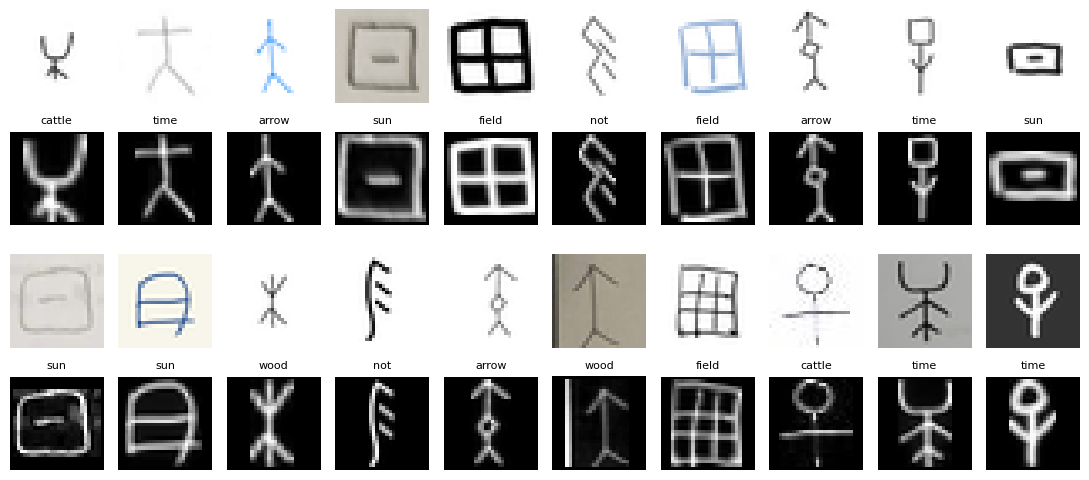

In [20]:
cls = np.load('class_handwriting.npz')
CLS = cls['images']
assert CLS.ndim == 4 and CLS.shape[1:] == (28, 28, 3) and CLS.dtype == np.uint8
CLS_CONV = np.stack([convert(im) for im in CLS])
pred_cls = pred_hw(final_net, CLS_CONV).astype(np.int64)


def check_prediction(p, n_images):
    p = np.asarray(p)
    assert p.shape == (n_images,), f'need shape ({n_images},), got {p.shape}'
    assert np.issubdtype(p.dtype, np.integer)
    assert p.min() >= 0 and p.max() <= 9
    print('OK:', p.shape, p.dtype, ' predicted count per class:', np.bincount(p, minlength=10))


check_prediction(pred_cls, len(CLS))
np.save(f'HW3_prediction_{SID}.npy', pred_cls)
back = np.load(f'HW3_prediction_{SID}.npy'); check_prediction(back, len(CLS))
assert (back == pred_cls).all()

fig, axes = plt.subplots(4, 10, figsize=(11, 5))
for j in range(20):
    a, b = axes[2 * (j // 10), j % 10], axes[2 * (j // 10) + 1, j % 10]
    a.imshow(CLS[j]); b.imshow(CLS_CONV[j]); b.set_title(NAMES[pred_cls[j]], fontsize=8)
    a.axis('off'); b.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/q62d_class_examples.png', dpi=130); plt.show()